# Applied Machine Learning (CSAI2017P) — Lab Assignment 3
## Time-Series Regression: Stock Price Prediction

Experiment 4 · CO2, CO4

| | |
|---|---|
| Name | *model solution* |
| SAP ID | — |
| Batch | — |
| Due | announced in the lab |
| Lab quiz | LQ3, after submission |

> **This is a worked solution.** Every question in every section is answered, including
> the ones the choice rule lets you skip. Your own submission only needs 2 of 3 in
> Section A and 1 of 2 in Section B.
>
> Datasets load through `aml_data.py`, which sits beside this notebook: it makes the
> canonical call from `Anchor-Datasets.pdf` and falls back to a CSV in `data/` when the
> campus network blocks the download.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn, __import__('matplotlib')):
    print(f"{m.__name__:12s} {m.__version__}")
print(f"{'python':12s} {sys.version.split()[0]}")

numpy        2.4.2
pandas       3.0.0
sklearn      1.8.0
matplotlib   3.10.8
python       3.13.11


## Load the data

One ticker, at least three years of daily history. `random_state` is set for the *model* here — the split is by date, never at random.

In [2]:
from aml_data import load_stock

TICKER = 'IBM'
s = load_stock(TICKER, start='2013-01-01')   # Date + Close, sorted ascending

print(f'{TICKER}: {len(s)} trading days, {s.Date.min().date()} -> {s.Date.max().date()}')
display(s.head())

IBM: 796 trading days, 2013-01-02 -> 2016-03-01


,Date,Close
0,2013-01-02,180.258852
1,2013-01-03,179.267358
2,2013-01-04,178.092257
3,2013-01-07,177.311910
4,2013-01-08,177.064033


---

# Section A — attempt any 2 of 3

*All three are answered below.*

## A1. Load and describe the series

*Dataset: C1, one ticker, ≥ 3 years.*

a. Load the daily history, parse the date column and sort ascending.
b. Plot the closing price and state the date range and number of trading days.
c. State in two lines why the row order matters here but did not in LA02.

dtype of Date: datetime64[us]
date range      : 2013-01-02 to 2016-03-01  (3.2 calendar years)
trading days    : 796
close range     : $117.85 to $198.95
first / last    : $180.26 / $134.37
calendar days in span: 1154 -> non-trading days are ABSENT, not zero


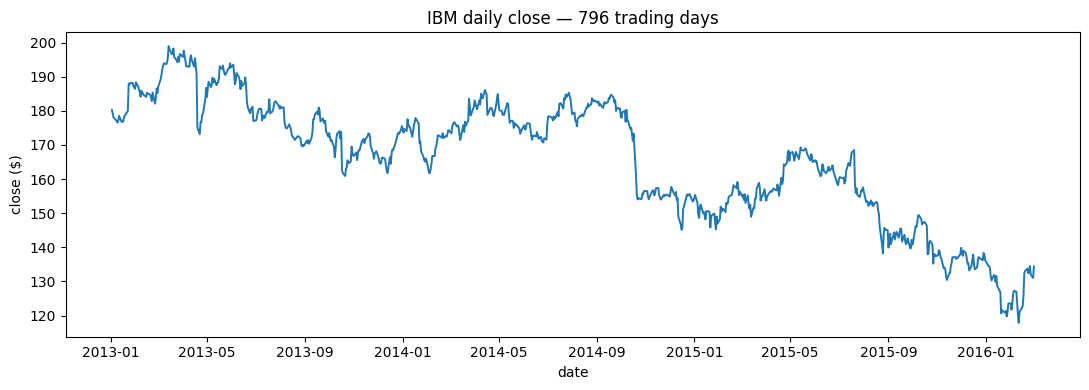

In [3]:
# A1 — code
# (a) the loader already parsed Date and sorted ascending; prove it
assert s.Date.is_monotonic_increasing
print("dtype of Date:", s.Date.dtype)

# (b) the facts the question asks for
span_years = (s.Date.max() - s.Date.min()).days / 365.25
print(f"date range      : {s.Date.min().date()} to {s.Date.max().date()}  "
      f"({span_years:.1f} calendar years)")
print(f"trading days    : {len(s)}")
print(f"close range     : ${s.Close.min():.2f} to ${s.Close.max():.2f}")
print(f"first / last    : ${s.Close.iloc[0]:.2f} / ${s.Close.iloc[-1]:.2f}")
print(f"calendar days in span: {(s.Date.max() - s.Date.min()).days} "
      f"-> non-trading days are ABSENT, not zero")

plt.figure(figsize=(11, 4))
plt.plot(s.Date, s.Close, lw=1.4)
plt.xlabel('date'); plt.ylabel('close ($)')
plt.title(f'{TICKER} daily close — {len(s)} trading days'); plt.tight_layout(); plt.show()

**Observation (A1):**

IBM daily closes, **2 January 2013 to 1 March 2016**: **796 trading days** over 3.2
calendar years, with closes between $117.85 and $198.95. The gap between 796 trading days
and roughly 1,150 calendar days is weekends and holidays — those rows are absent from the
file, not recorded as zero.

Row order matters here because every feature built below is *defined* by it: a lag is "the
value in the row before", a rolling mean is "the previous five rows", and the target is
"the row after". Shuffle the frame and all three point at arbitrary dates. In LA02 each row
was an independent district — nothing about district 900 depended on district 899, so the
order was an accident of the file. **Here the order is the data.**

## A2. Lag features

*Dataset: C1.*

a. Create features `Close_lag1`, `Close_lag2`, `Close_lag3` and a 5-day rolling mean.
b. Set the target to the next day's close. Show the first five rows of the resulting frame.
c. Explain in two lines why the first few rows must be dropped.

In [4]:
# A2 — code
f = s.copy()

for k in (1, 2, 3):
    f[f'Close_lag{k}'] = f.Close.shift(k)      # positive shift looks into the PAST

# shift(1) FIRST, then roll: without it, today's close is inside today's average
f['Close_roll5'] = f.Close.shift(1).rolling(5).mean()

f['target'] = f.Close.shift(-1)                # negative shift = tomorrow

print("rows before dropna:", len(f))
display(f.head(8))                             # the NaNs that must go are visible here

f = f.dropna().reset_index(drop=True)
print("rows after dropna :", len(f))
display(f.head())

FEATURES = ['Close', 'Close_lag1', 'Close_lag2', 'Close_lag3', 'Close_roll5']

rows before dropna: 796


,Date,Close,Close_lag1,Close_lag2,Close_lag3,Close_roll5,target
0,2013-01-02,180.258852,NaN,NaN,NaN,NaN,179.267358
1,2013-01-03,179.267358,180.258852,NaN,NaN,NaN,178.092257
2,2013-01-04,178.092257,179.267358,180.258852,NaN,NaN,177.311910
3,2013-01-07,177.311910,178.092257,179.267358,180.258852,NaN,177.064033
4,2013-01-08,177.064033,177.311910,178.092257,179.267358,NaN,176.559117
5,2013-01-09,176.559117,177.064033,177.311910,178.092257,178.398882,177.073222
6,2013-01-10,177.073222,176.559117,177.064033,177.311910,177.658935,178.514551
7,2013-01-11,178.514551,177.073222,176.559117,177.064033,177.220108,176.834521


rows after dropna : 790


,Date,Close,Close_lag1,Close_lag2,Close_lag3,Close_roll5,target
0,2013-01-09,176.559117,177.064033,177.311910,178.092257,178.398882,177.073222
1,2013-01-10,177.073222,176.559117,177.064033,177.311910,177.658935,178.514551
2,2013-01-11,178.514551,177.073222,176.559117,177.064033,177.220108,176.834521
3,2013-01-14,176.834521,178.514551,177.073222,176.559117,177.304567,176.724359
4,2013-01-15,176.724359,176.834521,178.514551,177.073222,177.209089,176.806980


**Observation (A2):**

The frame goes from **796 rows to 790**. Six rows are lost: the first five have no complete
5-day rolling window (and the first three no complete set of lags), and the last row has no
next day to predict.

They must be **dropped rather than filled**, because these values are not missing data —
the information does not exist. Imputing a lag with a column mean would invent a price that
was never traded, and filling the final target would invent a future; either one leaks a
fabricated number into training. scikit-learn would also refuse the NaNs outright.

## A3. The naive baseline

*Dataset: C1.*

a. Build the baseline that predicts tomorrow's close equals today's close.
b. Report its MAE and RMSE on your test period.
c. State in two lines why any model must beat this number to be interesting.

In [5]:
# A3 — code
from sklearn.metrics import mean_absolute_error, mean_squared_error

# chronological split: train on the past, test on the future. iloc, not train_test_split.
cut = int(len(f) * 0.8)
train, test = f.iloc[:cut], f.iloc[cut:]
print(f"train {len(train)} rows, {train.Date.iloc[0].date()} -> {train.Date.iloc[-1].date()}")
print(f"test  {len(test)} rows, {test.Date.iloc[0].date()} -> {test.Date.iloc[-1].date()}")

# persistence: the prediction IS today's close, so there is no model to fit
base_mae  = mean_absolute_error(test.target, test.Close)
base_rmse = np.sqrt(mean_squared_error(test.target, test.Close))

print(f"\npersistence MAE  ${base_mae:.3f}")
print(f"persistence RMSE ${base_rmse:.3f}")
print(f"mean close over the test period ${test.Close.mean():.2f} "
      f"-> MAE is {100 * base_mae / test.Close.mean():.2f}% of the price")

train 632 rows, 2013-01-09 -> 2015-07-14
test  158 rows, 2015-07-15 -> 2016-02-29

persistence MAE  $1.641
persistence RMSE $2.236
mean close over the test period $139.48 -> MAE is 1.18% of the price


**Observation (A3):**

Persistence — tomorrow's close equals today's close — gives **MAE $1.64** and **RMSE
$2.24** over the 158-day test period (15 July 2015 to 29 February 2016), on a mean price of
$139. That is a typical error of 1.2% from a rule with no features, no training and no
parameters.

Any model must beat it to be interesting because daily prices move slowly relative to their
level: yesterday's close already contains nearly all the information about today's. A model
reporting MAE $3 has not "achieved 98% accuracy" — it has lost to a one-line rule. The
baseline also fixes the units of the argument: the only meaningful claim is "X% better than
persistence", because a raw dollar error can be made to look small simply by choosing an
expensive stock.

---

# Section B — attempt any 1 of 2

*Both are answered below.*

## B1. Random split versus chronological split

*Dataset: C1.*

a. Train a `RandomForestRegressor` twice: once with `train_test_split(shuffle=True)`, once with the last 20% of dates held out.
b. Report test MAE for both and put them side by side.
c. Explain in 6–8 lines why the shuffled number is meaningless, naming the mechanism.

,split,test MAE ($)
0,shuffled (wrong),1.780
1,chronological (honest),11.670
2,persistence baseline,1.641


the shuffled split flatters the model by 6.6x

training price range: $145.14 - $198.95
test price range    : $117.85 - $168.48
forest's prediction range: $147.81 - $169.43


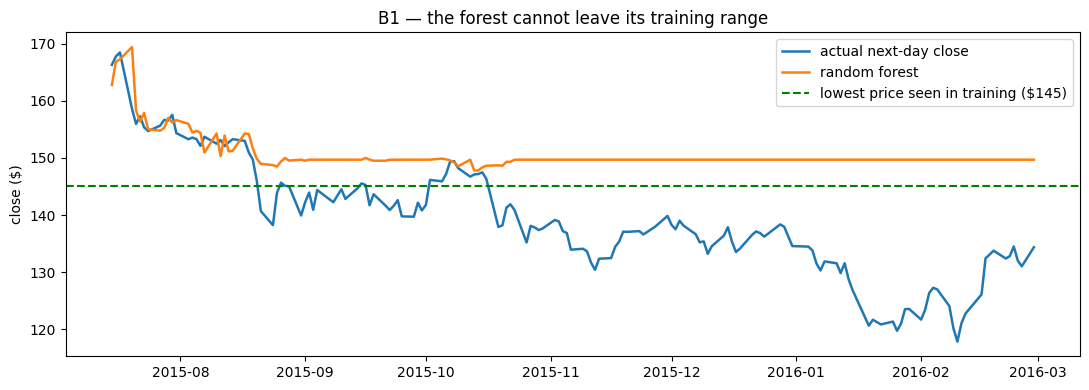

In [6]:
# B1 — code
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# (a) the WRONG way — rows drawn at random from anywhere in the three years
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    f[FEATURES], f.target, test_size=0.2, random_state=RANDOM_STATE, shuffle=True)
rf_shuffled = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_shuffled.fit(Xr_tr, yr_tr)
mae_shuffled = mean_absolute_error(yr_te, rf_shuffled.predict(Xr_te))

# (b) the HONEST way — train on the past, test on the future
rf_chrono = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_chrono.fit(train[FEATURES], train.target)
pred_chrono = rf_chrono.predict(test[FEATURES])
mae_chrono = mean_absolute_error(test.target, pred_chrono)

display(pd.DataFrame({
    'split': ['shuffled (wrong)', 'chronological (honest)', 'persistence baseline'],
    'test MAE ($)': [mae_shuffled, mae_chrono, base_mae],
}).round(3))
print(f"the shuffled split flatters the model by {mae_chrono / mae_shuffled:.1f}x")

# (c) the second mechanism, made visible
print(f"\ntraining price range: ${train.Close.min():.2f} - ${train.Close.max():.2f}")
print(f"test price range    : ${test.Close.min():.2f} - ${test.Close.max():.2f}")
print(f"forest's prediction range: ${pred_chrono.min():.2f} - ${pred_chrono.max():.2f}")

plt.figure(figsize=(11, 4))
plt.plot(test.Date, test.target, lw=1.8, label='actual next-day close')
plt.plot(test.Date, pred_chrono, lw=1.8, label='random forest')
plt.axhline(train.Close.min(), ls='--', color='green',
            label=f'lowest price seen in training (${train.Close.min():.0f})')
plt.ylabel('close ($)'); plt.legend(); plt.title('B1 — the forest cannot leave its training range')
plt.tight_layout(); plt.show()

**Observation (B1):**

Shuffled split: **MAE $1.78**. Chronological split: **MAE $11.67**. The same forest, the
same features, the same seed — a factor of seven, decided entirely by how the rows were
divided. (For reference, persistence scores $1.64, so the honest model **loses to doing
nothing**.)

The shuffled number is meaningless because a random split **leaks the future into
training**. Consecutive trading days differ by well under a dollar, so when 3 May sits in
the training set and 4 May in the test set, the model is not forecasting — it is
interpolating between days it has already been shown. That setting cannot exist in
practice, where every test day comes after every training day, so the number describes a
task nobody will ever face.

The honest split also exposes a second mechanism: a random forest predicts by averaging
training targets, so **its output can never leave the training range**. Trained on
$145–$199 and asked about a market falling to $118, it flat-lines at roughly $149 for the
final six months, as the plot shows. Between them, leakage and extrapolation are why $11.67
is the true measure of this model — and why modelling the *change* rather than the *level*
(see C1) is the right fix.

## B2. Horizon and difficulty

*Dataset: C1, chronological split throughout.*

a. Retrain your model to predict the close 1, 5 and 10 trading days ahead.
b. Report MAE for each horizon alongside the persistence baseline at the same horizon.
c. Plot MAE against horizon and explain the trend in 4–6 lines.

,horizon,model_MAE,baseline_MAE,model / baseline
0,1,11.670,1.641,7.114
1,5,14.443,3.652,3.954
2,10,16.306,5.296,3.079


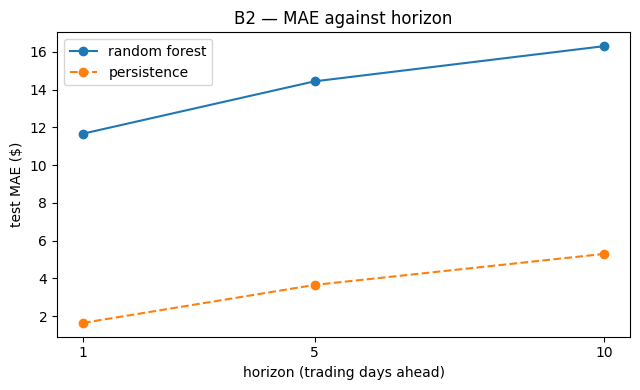

In [7]:
# B2 — code
def score_horizon(h):
    g = s.copy()
    for k in (1, 2, 3):
        g[f'Close_lag{k}'] = g.Close.shift(k)
    g['Close_roll5'] = g.Close.shift(1).rolling(5).mean()
    g['target'] = g.Close.shift(-h)                 # h days ahead, not 1
    g = g.dropna().reset_index(drop=True)

    c = int(len(g) * 0.8)
    tr, te = g.iloc[:c], g.iloc[c:]                 # chronological, every time
    m = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(tr[FEATURES], tr.target)
    return {
        'horizon': h,
        'model_MAE': mean_absolute_error(te.target, m.predict(te[FEATURES])),
        'baseline_MAE': mean_absolute_error(te.target, te.Close),   # baseline moves with h
    }

hz = pd.DataFrame([score_horizon(h) for h in (1, 5, 10)])
hz['model / baseline'] = hz.model_MAE / hz.baseline_MAE
display(hz.round(3))

plt.figure(figsize=(6.5, 4))
plt.plot(hz.horizon, hz.model_MAE, 'o-', label='random forest')
plt.plot(hz.horizon, hz.baseline_MAE, 'o--', label='persistence')
plt.xticks([1, 5, 10]); plt.xlabel('horizon (trading days ahead)'); plt.ylabel('test MAE ($)')
plt.legend(); plt.title('B2 — MAE against horizon'); plt.tight_layout(); plt.show()

**Observation (B2):**

MAE rises with the horizon for both: the forest goes **$11.67 → $14.44 → $16.31** and
persistence **$1.64 → $3.65 → $5.30**, at 1, 5 and 10 days ahead.

The baseline's trend is the informative one. A price that moves like a random walk
accumulates variance in proportion to elapsed time, so the typical distance from today's
price grows like $\sqrt{h}$ — and 1.64, 3.65, 5.30 is close to that pattern (√5 ≈ 2.2 and
√10 ≈ 3.2 times the one-day figure). The further ahead you ask, the more independent daily
moves separate the answer from anything observable today; there is simply less signal to
have.

The forest's line is flatter, but that is not the model improving with distance. Most of
its error at every horizon is the fixed cost of being unable to predict prices below its
training range, and that cost does not grow with $h$. **At no horizon does it beat the
baseline.**

---

# Section C — compulsory

## C1. Would you trade on it?

*Dataset: C1.*

a. Convert your best model's predictions into an up/down direction call and report directional accuracy.
b. In 4–6 lines, state whether a low MAE with near-50% directional accuracy is useful, and why.

returns model MAE  $1.620   (baseline $1.641)
directional accuracy 54.4% on 158 test days
share of up days     48.7%
standard error of a coin flip over 158 days: 4.0%  ->  1.1 SE from chance


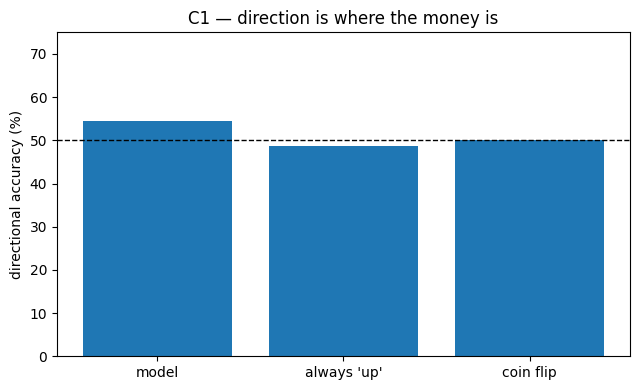

In [8]:
# C1 — code
# The price-level forest has MAE $11.67, so it is not a "low MAE" model at all.
# Model the RETURN instead: returns stay in the same range forever, so the
# extrapolation problem from B1 disappears.
g = s.copy()
g['ret'] = g.Close.pct_change()
for k in (1, 2, 3):
    g[f'ret_lag{k}'] = g.ret.shift(k)
g['ret_roll5']  = g.ret.shift(1).rolling(5).mean()
g['target_ret'] = g.Close.pct_change().shift(-1)
g = g.dropna().reset_index(drop=True)

RFEAT = ['ret', 'ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_roll5']
c = int(len(g) * 0.8)
rtr, rte = g.iloc[:c], g.iloc[c:]

rf_ret = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_ret.fit(rtr[RFEAT], rtr.target_ret)
pred_ret = rf_ret.predict(rte[RFEAT])

# back to dollars so the MAE is comparable with A3
pred_price = rte.Close.values * (1 + pred_ret)
true_price = rte.Close.values * (1 + rte.target_ret.values)
mae_ret  = mean_absolute_error(true_price, pred_price)
base_ret = mean_absolute_error(true_price, rte.Close.values)

# (a) directional accuracy
up_pred = pred_ret > 0
up_true = rte.target_ret.values > 0
acc = (up_pred == up_true).mean()
n = len(rte)

print(f"returns model MAE  ${mae_ret:.3f}   (baseline ${base_ret:.3f})")
print(f"directional accuracy {acc:.1%} on {n} test days")
print(f"share of up days     {up_true.mean():.1%}")
print(f"standard error of a coin flip over {n} days: "
      f"{np.sqrt(0.25 / n):.1%}  ->  {abs(acc - 0.5) / np.sqrt(0.25 / n):.1f} SE from chance")

plt.figure(figsize=(6.5, 4))
plt.bar(['model', "always 'up'", 'coin flip'],
        [acc * 100, up_true.mean() * 100, 50])
plt.axhline(50, ls='--', color='k', lw=1)
plt.ylabel('directional accuracy (%)'); plt.ylim(0, 75)
plt.title('C1 — direction is where the money is'); plt.tight_layout(); plt.show()

**Observation (C1):**

The returns model reaches **MAE $1.62** against the persistence baseline's **$1.64**, and
calls the direction correctly on **54.4%** of 158 test days.

No, I would not trade on it. A low MAE with near-chance directional accuracy is not useful
because the two quantities measure different things. **MAE is dominated by the level**:
predicting "about the same as today" is nearly right every single day, which is why the
baseline already scores $1.64 and why my model's two-cent improvement is noise rather than
insight. **Every decision you would actually take — buy, sell, hold — depends only on the
sign of the change.** On the sign this model is at 54.4%, where chance is 50% and the
standard error over 158 days is $\sqrt{0.25/158} = 4.0$ percentage points; the result is
about one standard error from chance, the kind of gap that appears and vanishes when you
change the ticker, the window or the seed.

Before costs it is indistinguishable from a coin flip; after brokerage and spread on 158
daily round trips it is a reliable way to lose money. The honest report is that the model
matches the naive baseline on MAE and adds nothing on direction.

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA03_<SAPID>.ipynb`, `README.md` beside it
- [x] No datasets uploaded — the loading code is enough
